# 07 Model figures

This notebook draws the figures for the report and the slides from results that notebooks 01, 02 and 05 have already saved. Nothing is trained here, and the test years stay closed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import EXPERIMENT_LOG_PATH, TABLES_DIR, TEST_YEARS, TRAIN_YEARS, VAL_YEARS
from src.split import TIME_FOLDS
from src.style import AQUA, BLUE, GRID, INK, MUTED, ORANGE, apply_style, save_figure

apply_style()

## 1. How the data is split over time

Tuning uses three folds inside the training years, each fitted on the past and checked on the years after it. The final model is fitted on all training years, compared and calibrated on validation, and checked once on the test years.

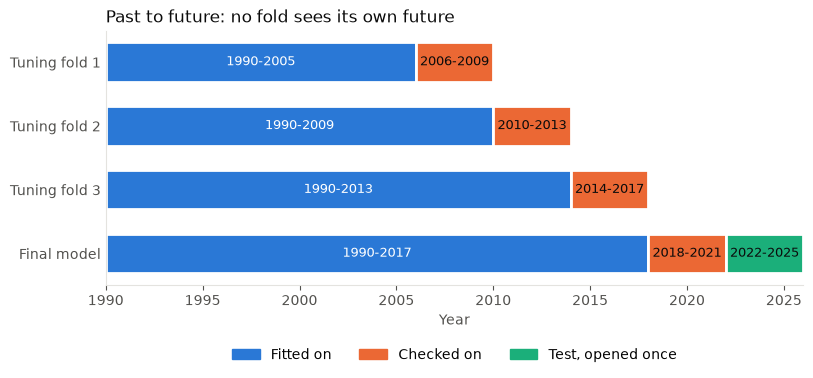

Tuning fold 1 [(1990, 2005), (2006, 2009)]
Tuning fold 2 [(1990, 2009), (2010, 2013)]
Tuning fold 3 [(1990, 2013), (2014, 2017)]
Final model [(1990, 2017), (2018, 2021), (2022, 2025)]


In [2]:
FIRST, LAST = TRAIN_YEARS[0], TEST_YEARS[1]
rows = [(f"Tuning fold {i}", [(past, BLUE, "white"), (future, ORANGE, INK)]) for i, (past, future) in enumerate(TIME_FOLDS, 1)]
rows.append(("Final model", [(TRAIN_YEARS, BLUE, "white"), (VAL_YEARS, ORANGE, INK), (TEST_YEARS, AQUA, INK)]))

fig, ax = plt.subplots(figsize=(9, 3.3))
for y, (_, spans) in zip(range(len(rows), 0, -1), rows):
    for (start, end), color, ink in spans:
        ax.barh(y, end - start + 1, left=start, height=0.62, color=color, edgecolor="white", linewidth=2)
        ax.text((start + end + 1) / 2, y, f"{start}-{end}", ha="center", va="center", color=ink, fontsize=9)
ax.set_yticks(range(len(rows), 0, -1), [name for name, _ in rows])
ax.set_xlim(FIRST, LAST + 1)
ax.set_xlabel("Year")
ax.tick_params(axis="y", length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in (BLUE, ORANGE, AQUA)]
ax.legend(handles, ["Fitted on", "Checked on", "Test, opened once"], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.set_title("Past to future: no fold sees its own future", loc="left", fontsize=12)
save_figure(fig, "07_time_folds.png")
plt.show()
for name, spans in rows:
    print(name, [span for span, _, _ in spans])

## 2. Tuning history

Both searches minimize log loss on the time folds, drawn here on one scale. CatBoost had 30 trials and LightGBM 12.

CatBoost, 30 trials: best 0.6361 at trial 19
LightGBM, 12 trials: best 0.6307 at trial 7


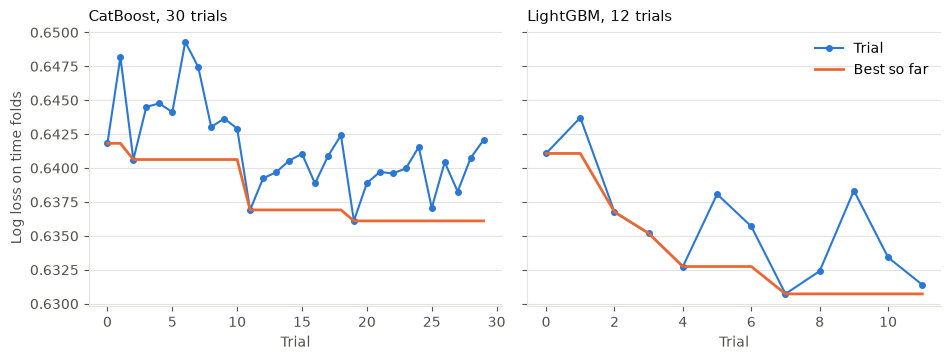

In [3]:
histories = {"CatBoost, 30 trials": "02_optuna_catboost_trials.csv", "LightGBM, 12 trials": "02_optuna_lightgbm_trials.csv"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, gridspec_kw={"wspace": 0.06})
for ax, (title, name) in zip(axes, histories.items()):
    trials = pd.read_csv(TABLES_DIR / name).sort_values("number")
    ax.plot(trials["number"], trials["value"], "o-", ms=4, lw=1.5, color=BLUE, label="Trial")
    ax.plot(trials["number"], trials["value"].cummin(), lw=2, color=ORANGE, label="Best so far")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Trial")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    print(f"{title}: best {trials['value'].min():.4f} at trial {int(trials['value'].idxmin())}")
axes[0].set_ylabel("Log loss on time folds")
axes[1].legend(frameon=False, loc="upper right")
save_figure(fig, "07_tuning_history.png")
plt.show()

## 3. Model comparison on validation

Rows come from the experiment log. The intervals resample whole expeditions, and the wider level is in `05_paired_by_level.csv`.

                     roc_auc  roc_auc_lo  roc_auc_hi  brier  log_loss
Rule: peak x season    0.601       0.567       0.632  0.250     0.693
Logistic regression    0.686       0.656       0.716  0.228     0.656
CatBoost, typical      0.689       0.657       0.721  0.224     0.639
CatBoost, tuned        0.693       0.662       0.724  0.224     0.639
LightGBM, tuned        0.712       0.683       0.739  0.216     0.622


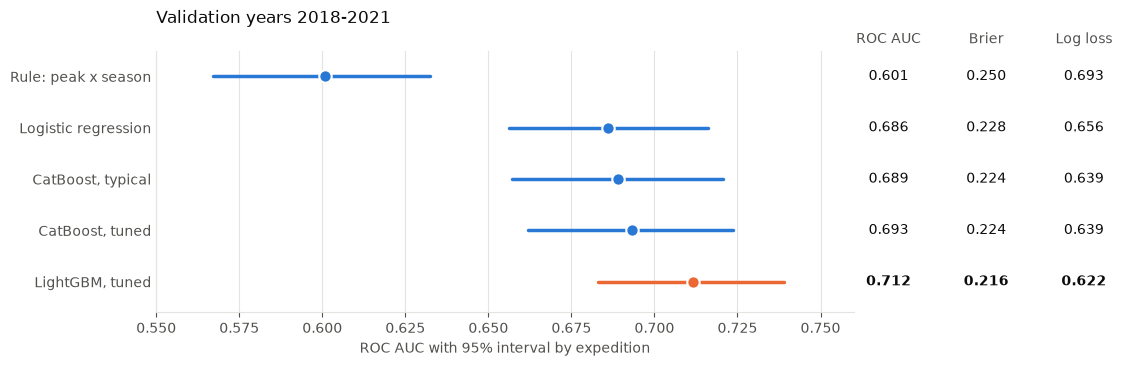

In [4]:
MODELS = {
    "Rule: peak x season rate": "Rule: peak x season",
    "Logistic regression, age hinge at 40": "Logistic regression",
    "CatBoost typical (5 seeds)": "CatBoost, typical",
    "CatBoost tuned (5 seeds)": "CatBoost, tuned",
    "LightGBM tuned (5 seeds)": "LightGBM, tuned",
}
log = pd.read_csv(EXPERIMENT_LOG_PATH)
log = log[log["view"] == "val_all"].drop_duplicates("model", keep="last").set_index("model")
table = log.loc[list(MODELS), ["roc_auc", "roc_auc_lo", "roc_auc_hi", "brier", "log_loss"]]
table.index = list(MODELS.values())
print(table.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(table), 0, -1)
for yy, (name, row) in zip(y, table.iterrows()):
    final = name == "LightGBM, tuned"
    ax.plot([row["roc_auc_lo"], row["roc_auc_hi"]], [yy, yy], color=ORANGE if final else BLUE, lw=2.5, solid_capstyle="round")
    ax.scatter(row["roc_auc"], yy, s=80, color=ORANGE if final else BLUE, edgecolors="white", linewidths=1.5, zorder=3)
    weight = "bold" if final else "normal"
    transform = ax.get_yaxis_transform()
    for x, column in ((1.05, "roc_auc"), (1.19, "brier"), (1.33, "log_loss")):
        ax.text(x, yy, f"{row[column]:.3f}", transform=transform, ha="center", va="center", color=INK, fontsize=10, fontweight=weight)
for x, label in ((1.05, "ROC AUC"), (1.19, "Brier"), (1.33, "Log loss")):
    ax.text(x, len(table) + 0.72, label, transform=ax.get_yaxis_transform(), ha="center", va="center", color=MUTED, fontsize=10)
ax.set_yticks(y, table.index)
ax.set_ylim(0.4, len(table) + 0.5)
ax.set_xlim(0.55, 0.76)
ax.set_xlabel("ROC AUC with 95% interval by expedition")
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Validation years 2018-2021", loc="left", fontsize=12, pad=20)
save_figure(fig, "07_model_comparison.png")
plt.show()

## 4. What made LightGBM better

We changed one setting at a time. The tuned model with weak category smoothing falls furthest, so smoothing rare categories is the main cause.

variant
Tuned, weak category smoothing        0.678
CatBoost, typical (for reference)     0.689
Tuned, no categorical features        0.689
LightGBM, default                     0.690
Default + tuned category smoothing    0.704
Tuned, no row and column sampling     0.707
LightGBM, tuned                       0.712


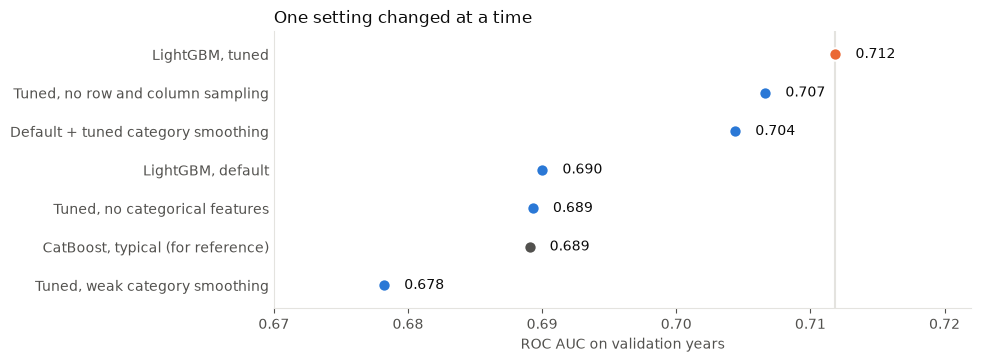

In [5]:
LABELS = {
    "tuned LightGBM": "LightGBM, tuned",
    "tuned, no row and column sampling": "Tuned, no row and column sampling",
    "default + category smoothing as tuned": "Default + tuned category smoothing",
    "default LightGBM": "LightGBM, default",
    "tuned, no categorical features": "Tuned, no categorical features",
    "tuned, weak category smoothing": "Tuned, weak category smoothing",
}
why = pd.read_csv(TABLES_DIR / "02_why_lightgbm.csv").set_index("variant")["val_roc_auc"].rename(index=LABELS)
why["CatBoost, typical (for reference)"] = log.loc["CatBoost typical (5 seeds)", "roc_auc"]
why = why.sort_values()
print(why.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(why))
ax.axvline(why["LightGBM, tuned"], color=GRID, lw=1.5, zorder=1)
for yy, (name, value) in zip(y, why.items()):
    color = ORANGE if name == "LightGBM, tuned" else MUTED if name.startswith("CatBoost") else BLUE
    ax.scatter(value, yy, s=80, color=color, edgecolors="white", linewidths=1.5, zorder=3)
    ax.text(value + 0.0015, yy, f"{value:.3f}", va="center", color=INK, fontsize=10)
ax.set_yticks(y, why.index)
ax.set_xlim(0.67, 0.722)
ax.set_ylim(-0.6, len(why) - 0.4)
ax.set_xlabel("ROC AUC on validation years")
ax.tick_params(axis="y", length=0)
ax.set_title("One setting changed at a time", loc="left", fontsize=12)
save_figure(fig, "07_why_lightgbm.png")
plt.show()